<a href="https://colab.research.google.com/github/namgiju/mlprog/blob/main/car_d.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

drive.mount('/content/drive')

columns = [
    'buying', 'maint', 'doors',
    'persons', 'lug_boot', 'safety', 'class'
]

df = pd.read_csv(
    '/content/drive/MyDrive/car.data',
    header=None,
    names=columns
)

print(df.shape)
print(df.head())
print(df.isnull().sum())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(1728, 7)
  buying  maint doors persons lug_boot safety  class
0  vhigh  vhigh     2       2    small    low  unacc
1  vhigh  vhigh     2       2    small    med  unacc
2  vhigh  vhigh     2       2    small   high  unacc
3  vhigh  vhigh     2       2      med    low  unacc
4  vhigh  vhigh     2       2      med    med  unacc
buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64


X, y 분리 및 레이블 변환

In [11]:
X = df.drop('class', axis=1)
y = df['class']

# 입력 데이터를 원-핫 인코딩
X = pd.get_dummies(X, dtype=int)

# 정답 레이블 숫자로 변환
class_names = ['unacc', 'acc', 'good', 'vgood']

label_map = {
    'unacc': 0,
    'acc': 1,
    'good': 2,
    'vgood': 3
}

y = y.map(label_map)

# 레이블 누락 검사
print("입력 데이터 크기:", X.shape)
print("레이블별 개수:")
print(y.value_counts().sort_index())

assert y.isna().sum() == 0
assert set(y.unique()) == {0, 1, 2, 3}

입력 데이터 크기: (1728, 21)
레이블별 개수:
class
0    1210
1     384
2      69
3      65
Name: count, dtype: int64


학습용 / 테스트용 분리

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("학습 데이터:", X_train.shape)
print("테스트 데이터:", X_test.shape)

print("학습 레이블:")
print(y_train.value_counts().sort_index())

print("테스트 레이블:")
print(y_test.value_counts().sort_index())

학습 데이터: (1382, 21)
테스트 데이터: (346, 21)
학습 레이블:
class
0    968
1    307
2     55
3     52
Name: count, dtype: int64
테스트 레이블:
class
0    242
1     77
2     14
3     13
Name: count, dtype: int64


딥러닝 모델 생성 및 학습

In [13]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(4, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,620 (14.14 KB)

 Trainable params: 3,620 (14.14 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6769 - loss: 0.9873 - val_accuracy: 0.7184 - val_loss: 0.7944
Epoch 2/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6959 - loss: 0.7265 - val_accuracy: 0.7220 - val_loss: 0.6340
Epoch 3/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7421 - loss: 0.5714 - val_accuracy: 0.7726 - val_loss: 0.4827
Epoch 4/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8407 - loss: 0.4324 - val_accuracy: 0.8339 - val_loss: 0.3675
Epoch 5/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8733 - loss: 0.3338 - val_accuracy: 0.8484 - val_loss: 0.3003
Epoch 6/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8932 - loss: 0.2736 - val_accuracy: 0.9061 - val_loss: 0.2542
Epoch 7/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9195 - loss: 0.2281 - val_accuracy: 0.9097 - val_loss: 0.2217
Epoch 8/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9267 - loss: 0.1964 - val_accuracy: 0.9170 - v

정확도 및 레이블별 성능 평가

In [14]:
loss, accuracy = model.evaluate(X_test, y_test)

print("테스트 정확도:", accuracy)

pred = model.predict(X_test)
pred_class = np.argmax(pred, axis=1)

print(classification_report(
    y_test,
    pred_class,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    zero_division=0
))

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9942 - loss: 0.0156     
테스트 정확도: 0.9942196607589722
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
              precision    recall  f1-score   support

       unacc       1.00      1.00      1.00       242
         acc       1.00      0.99      0.99        77
        good       1.00      0.93      0.96        14
       vgood       0.93      1.00      0.96        13

    accuracy                           0.99       346
   macro avg       0.98      0.98      0.98       346
weighted avg       0.99      0.99      0.99       346



혼동행렬 출력

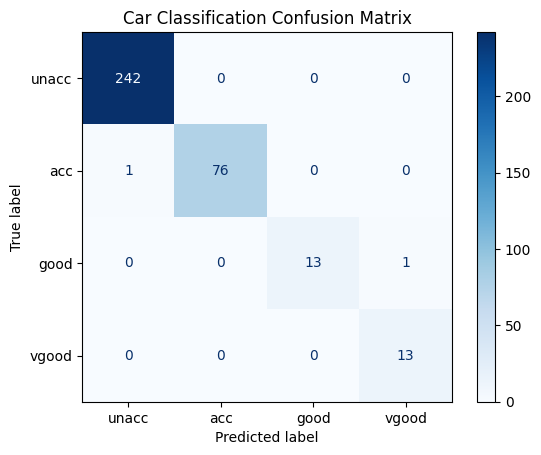

In [15]:
cm = confusion_matrix(
    y_test,
    pred_class,
    labels=[0, 1, 2, 3]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap='Blues')
plt.title('Car Classification Confusion Matrix')
plt.show()

학습 그래프 출력

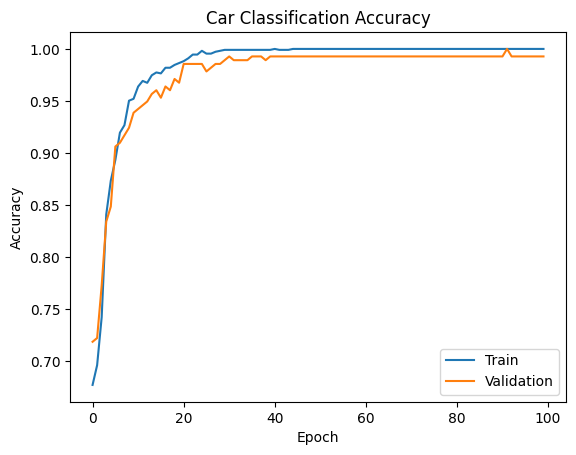

In [16]:
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Car Classification Accuracy')
plt.legend()
plt.show()